<a id = "1"></a><h1 id="Salary Prediction with Machine Learning"><span class="label label-default" style="background-color:#f5c0c0; font-size:30px; 
color: Black; ">Store Item Demand Forecasting</span></h1>


## Importing Libraries

In [50]:
import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

## Exploring data analysis

In [3]:
test_data = pd.read_csv(r'..\dataset\test (2).csv')
train_data = pd.read_csv(r'..\dataset\train.csv')

In [4]:
print("Train Data Shape:", train_data.shape)
print("Test Data Shape:", test_data.shape)

Train Data Shape: (913000, 4)
Test Data Shape: (45000, 4)


In [5]:
print("Train Data Shape:", train_data.shape)
print("Test Data Shape:", test_data.shape)

Train Data Shape: (913000, 4)
Test Data Shape: (45000, 4)


In [6]:
train_data.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [7]:
train_data.isna().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [8]:
test_data.isna().sum()

id       0
date     0
store    0
item     0
dtype: int64

In [9]:
print(train_data.info())
print("-" * 50)
print(test_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB
None
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      45000 non-null  int64
 1   date    45000 non-null  str  
 2   store   45000 non-null  int64
 3   item    45000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.8 MB
None


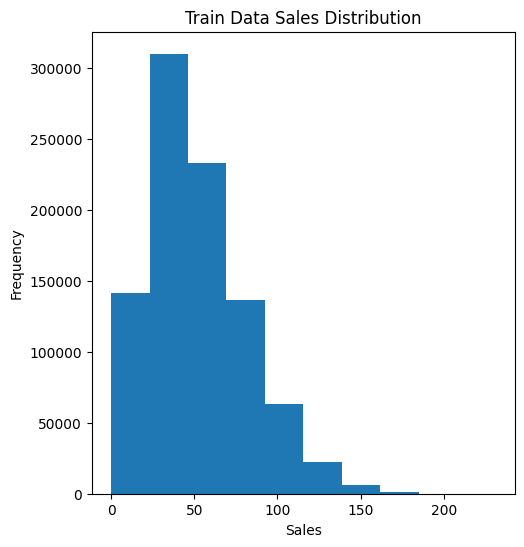

In [10]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(train_data['sales'])
plt.title('Train Data Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

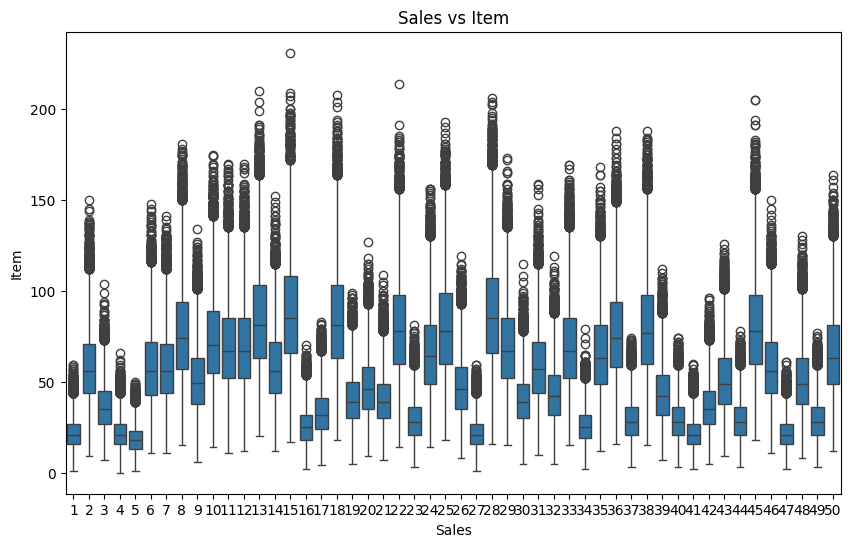

In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_data, x="item", y="sales")
plt.title('Sales vs Item')
plt.xlabel('Sales')
plt.ylabel('Item')
plt.show()

In [12]:
selected=train_data.select_dtypes(include=['int']).columns
for i in selected:
    print(f"column : ",{i},"\n","unique : ",{train_data[i].nunique()})

column :  {'store'} 
 unique :  {10}
column :  {'item'} 
 unique :  {50}
column :  {'sales'} 
 unique :  {213}


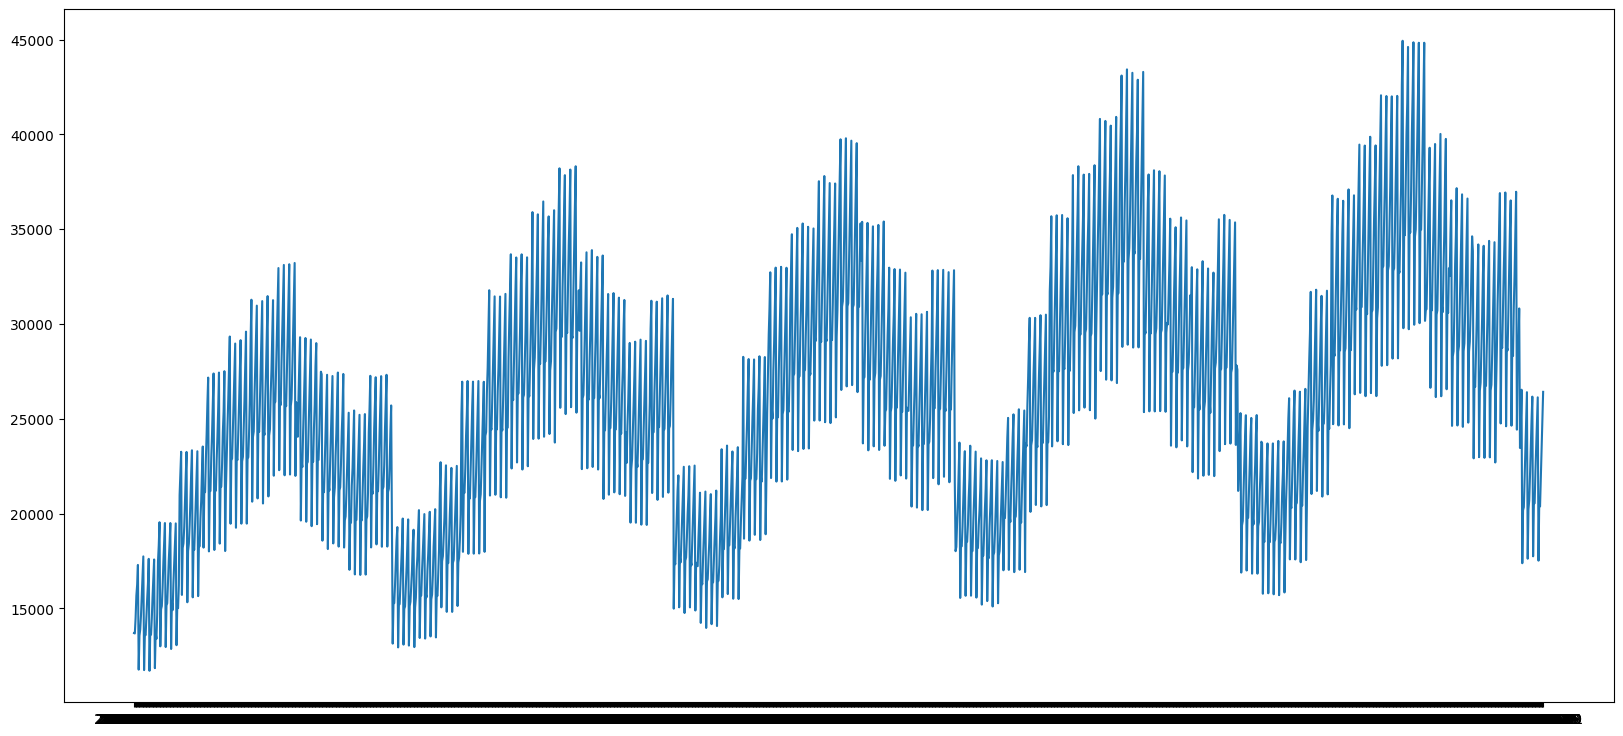

In [13]:
daily_sales = train_data.groupby("date")["sales"].sum()

plt.figure(figsize=(20,9))
plt.plot(daily_sales)

In [14]:
train_data["date"] = pd.to_datetime(train_data["date"])

train_data["year"] = train_data["date"].dt.year

yearly_sales = train_data.groupby("year")["sales"].sum()

In [15]:
train_data.head()

,date,store,item,sales,year
0,2013-01-01,1,1,13,2013
1,2013-01-02,1,1,11,2013
2,2013-01-03,1,1,14,2013
3,2013-01-04,1,1,13,2013
4,2013-01-05,1,1,10,2013


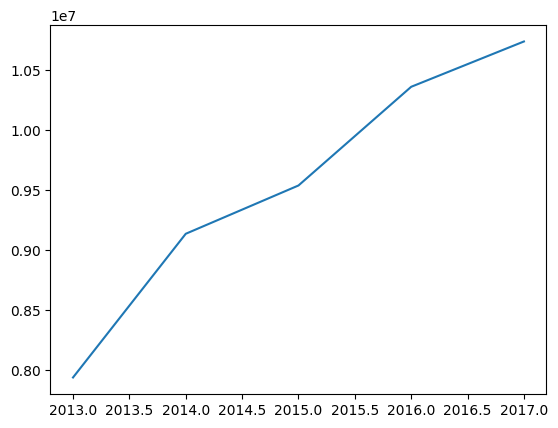

In [16]:
plt.plot(yearly_sales)

In [17]:
train_data["month"] = train_data["date"].dt.month

monthly_sales = train_data.groupby("month")["sales"].sum()

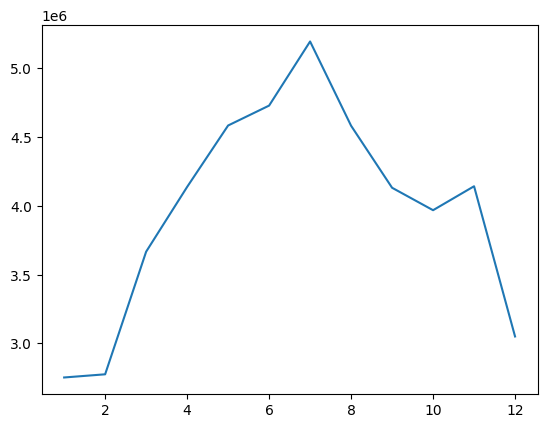

In [18]:
plt.plot(monthly_sales)

In [19]:
train_data["weekday"] = train_data["date"].dt.day_name()

weekday_sales = train_data.groupby("weekday")["sales"].sum()

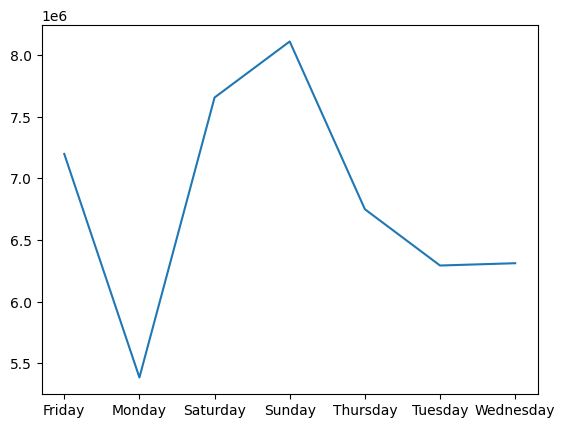

In [20]:
plt.plot(weekday_sales)

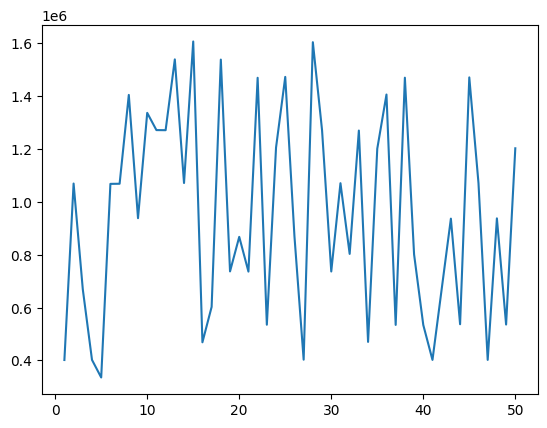

In [21]:
plt.plot(train_data.groupby("item")["sales"].sum())

In [24]:
train_data["day"] = train_data["date"].dt.day

In [26]:
train_data["quarter"] = train_data["date"].dt.quarter

In [28]:
train_data["is_weekend"] = train_data["date"].dt.weekday.isin([5, 6]).astype(int)

In [29]:
train_data.tail()

,date,store,item,sales,year,month,weekday,day,quarter,is_weekend
912995,2017-12-27,10,50,63,2017,12,Wednesday,27,4,0
912996,2017-12-28,10,50,59,2017,12,Thursday,28,4,0
912997,2017-12-29,10,50,74,2017,12,Friday,29,4,0
912998,2017-12-30,10,50,62,2017,12,Saturday,30,4,1
912999,2017-12-31,10,50,82,2017,12,Sunday,31,4,1


In [31]:
train_data["lag_1"] = (
    train_data
    .groupby(["store", "item"])["sales"]
    .shift(1)
)

In [36]:
train_data.head()

,date,store,item,sales,year,month,weekday,day,quarter,is_weekend,lag_1,lag_7,lag_30
0,2013-01-01,1,1,13,2013,1,Tuesday,1,1,0,NaN,NaN,NaN
1,2013-01-02,1,1,11,2013,1,Wednesday,2,1,0,13.0,NaN,NaN
2,2013-01-03,1,1,14,2013,1,Thursday,3,1,0,11.0,NaN,NaN
3,2013-01-04,1,1,13,2013,1,Friday,4,1,0,14.0,NaN,NaN
4,2013-01-05,1,1,10,2013,1,Saturday,5,1,1,13.0,NaN,NaN


In [33]:
train_data["lag_7"] = (
    train_data
    .groupby(["store", "item"])["sales"]
    .shift(7)
)

In [35]:
train_data["lag_30"] = (
    train_data
    .groupby(["store", "item"])["sales"]
    .shift(30)
)

In [37]:
train_data[
    (train_data["store"] == 1) &
    (train_data["item"] == 1)
].head(10)

,date,store,item,sales,year,month,weekday,day,quarter,is_weekend,lag_1,lag_7,lag_30
0,2013-01-01,1,1,13,2013,1,Tuesday,1,1,0,NaN,NaN,NaN
1,2013-01-02,1,1,11,2013,1,Wednesday,2,1,0,13.0,NaN,NaN
2,2013-01-03,1,1,14,2013,1,Thursday,3,1,0,11.0,NaN,NaN
3,2013-01-04,1,1,13,2013,1,Friday,4,1,0,14.0,NaN,NaN
4,2013-01-05,1,1,10,2013,1,Saturday,5,1,1,13.0,NaN,NaN
5,2013-01-06,1,1,12,2013,1,Sunday,6,1,1,10.0,NaN,NaN
6,2013-01-07,1,1,10,2013,1,Monday,7,1,0,12.0,NaN,NaN
7,2013-01-08,1,1,9,2013,1,Tuesday,8,1,0,10.0,13.0,NaN
8,2013-01-09,1,1,12,2013,1,Wednesday,9,1,0,9.0,11.0,NaN
9,2013-01-10,1,1,9,2013,1,Thursday,10,1,0,12.0,14.0,NaN


In [38]:
train_data["rolling_mean_7"] = (
    train_data
    .groupby(["store", "item"])["sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

In [39]:
train_data["rolling_mean_30"] = (
    train_data
    .groupby(["store", "item"])["sales"]
    .transform(lambda x: x.shift(1).rolling(30).mean())
)

In [60]:
train_data = train_data.dropna().reset_index(drop=True)

In [61]:
train_data[
    (train_data["store"] == 1) &
    (train_data["item"] == 1)
][["date", "sales", "lag_1", "lag_7", "rolling_mean_7"]].head(15)

,date,sales,lag_1,lag_7,rolling_mean_7
0,2013-01-31,13,9.0,8.0,10.285714
1,2013-02-01,11,13.0,14.0,11.000000
2,2013-02-02,21,11.0,12.0,10.571429
3,2013-02-03,15,21.0,12.0,11.857143
4,2013-02-04,14,15.0,11.0,12.285714
5,2013-02-05,9,14.0,6.0,12.714286
6,2013-02-06,10,9.0,9.0,13.142857
7,2013-02-07,13,10.0,13.0,13.285714
8,2013-02-08,11,13.0,11.0,13.285714
9,2013-02-09,14,11.0,21.0,13.285714


In [62]:
train = train_data[train_data["date"] < "2017-01-01"]
test = train_data[train_data["date"] >= "2017-01-01"]

In [72]:
print(train.shape)
print(test.shape)

(715500, 15)
(182500, 15)


In [64]:
print(train["date"].min())
print(train["date"].max())

print(test["date"].min())
print(test["date"].max())

2013-01-31 00:00:00
2016-12-31 00:00:00
2017-01-01 00:00:00
2017-12-31 00:00:00


In [65]:
features = [
    "store",
    "item",
    "year",
    "month",
    "day",
    "quarter",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_30"
]

In [66]:
target = "sales"

In [67]:
X_train = train[features]
y_train = train[target]

In [68]:
X_test = test[features]
y_test = test[target]

In [69]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(715500, 12)
(715500,)
(182500, 12)
(182500,)


In [70]:
model = LinearRegression()

In [71]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [73]:
predictions = model.predict(X_test)

In [74]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions
})

comparison.head(10)

,Actual,Predicted
1431,19,25.882423
1432,15,16.306425
1433,10,13.954643
1434,16,16.502003
1435,14,18.301878
1436,24,18.380128
1437,14,23.239773
1438,20,25.438490
1439,18,16.267202
1440,11,14.319251


In [75]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 7.428497962218064
RMSE: 9.730857494667708
R2  : 0.904888809192912


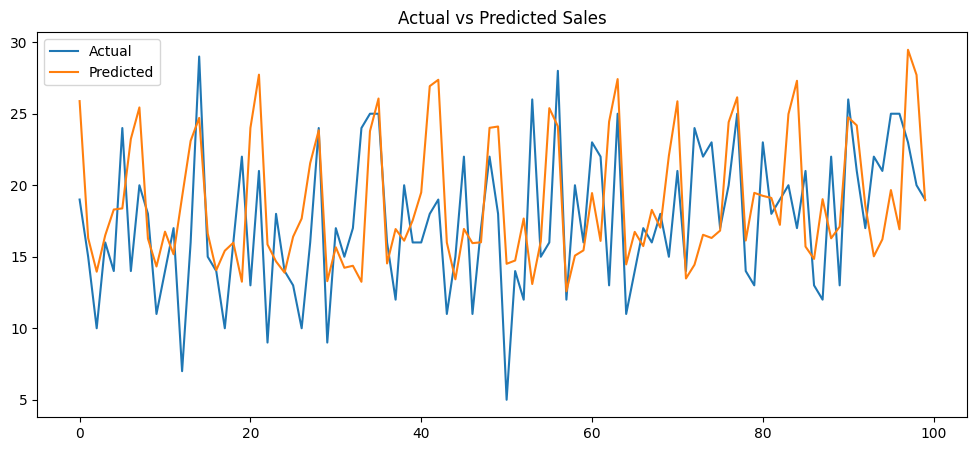

In [79]:
plt.figure(figsize=(12,5))

plt.plot(y_test.values[:100], label="Actual")
plt.plot(predictions[:100], label="Predicted")

plt.legend()
plt.title("Actual vs Predicted Sales")
plt.show()

In [82]:
import joblib

joblib.dump(model, "../models/sales_forecasting_model.pkl")

['../models/sales_forecasting_model.pkl']

In [83]:
joblib.dump(features, "../models/features.pkl")

['../models/features.pkl']